# Additional experiments (revision, Bioengineering-4723886)

Additional experiments performed during the revision (November 2026), after the models of the paper had been locked. The results of the original analysis (`results_v2`) are read but never modified; new results are saved in a separate results folder.

| Part | Topic | Experiment |
|---|---|---|
| A | Training duration | ResNet50 with stage 1 extended to 30 epochs and early-stopping patience 15 |
| B | Transfer learning | ResNet50: from random weights / frozen backbone / top 30% fine-tuned (paper protocol) / all layers fine-tuned |
| C | Augmentation | ResNet50: no augmentation and additional colour augmentation versus the standard augmentation |
| D | Run-to-run variability | Seeds 3 and 4 for all seven models (seeds 0–2 are reused from `results_v2`, not retrained) |
| E | Figures | Corrected Figure 3 (integer epochs) and examples of augmented images (Figure S6) |

Parts A–C use seeds 0–4. Training runs are executed in separate worker processes; completed runs are skipped when the notebook is re-run.

External results of the new runs are **exploratory only**: they were not used to select or modify any model, and the locked models of the paper are unchanged.

## Step 1 - Connect Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!nvidia-smi --query-gpu=name,memory.total --format=csv

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
name, memory.total [MiB]
Tesla T4, 15360 MiB


## Step 2 - Shared code and settings
This cell writes the settings, model and training code to `/content/r1_common.py`, which is used by this notebook and by the training worker.
The protocol is identical to that of the paper unless an experiment changes it.

In [ ]:
%%writefile /content/r1_common.py
# Shared code for this notebook and its training worker (written by the notebook)
import os, json, time, random, platform, warnings
import numpy as np, pandas as pd
import tensorflow as tf, keras
from keras import layers, ops
from PIL import Image, ImageOps
from scipy import stats
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
warnings.filterwarnings("ignore", category=UserWarning); warnings.filterwarnings("ignore", category=RuntimeWarning)
tf.get_logger().setLevel("ERROR")
pd.set_option("display.width", 220, "display.max_columns", 40)

from pathlib import Path
PROJECT    = Path('/content/drive/MyDrive/oral project')
CLEAN_DIR  = PROJECT / 'oral_clean'
EXT_DIR    = PROJECT / 'external_piyarathne'
RESULTS_V2 = PROJECT / 'results_v2'            # original results: READ ONLY
OUT        = PROJECT / 'results_reviewer1'     # all new results go here

MODELS = ["ResNet50", "VGG16", "MobileNetV2", "DenseNet121", "EfficientNetB0", "Xception", "InceptionV3"]
PRIMARY_MODEL = "ResNet50"

# ---- protocol of the paper (do not change) ----
IMG_SIZE, BATCH_SIZE = 224, 16
HEAD_EPOCHS, HEAD_LR = 10, 1e-3
FT_EPOCHS,   FT_LR   = 40, 1e-5
FT_FRACTION = 0.30
DENSE_UNITS, DROPOUT = 256, 0.30
ES_PATIENCE, LR_PATIENCE, LR_FACTOR, MIN_LR = 5, 2, 0.5, 1e-7
THRESHOLD = 0.5
AUG = dict(flip="horizontal", rotation_deg=15, translation=0.10, zoom=0.10, brightness=0.10)

# ---- settings used only by the new experiments ----
SCRATCH_LR, SCRATCH_EPOCHS, SCRATCH_PATIENCE = 1e-4, 100, 10   # training from random weights needs more epochs
FROZEN_EPOCHS = 50                                            # frozen backbone: allow the head to converge fully
COLOR_AUG = dict(contrast=0.15, saturation=(0.40, 0.60), hue=0.03)   # mild colour jitter (Part C)

ABLATION_SEEDS = [0, 1, 2, 3, 4]          # Parts A-C: 5 seeds each
ALL_SEEDS      = list(range(5))          # Part D: seeds 0-4 per model (0-2 already exist in results_v2)
RUN_PART_D     = True                     # set False to skip the additional seeds (Part D)

# Each experiment = changes relative to the paper's protocol
EXPERIMENTS = {
    "baseline":   dict(),                                          # the paper's protocol (top 30% fine-tuned)
    "patience15": dict(head_epochs=30, es_patience=15),            # Part A
    "scratch":    dict(mode="scratch"),                            # Part B: no ImageNet weights
    "frozen":     dict(mode="frozen"),                             # Part B: ImageNet features, head only
    "full_ft":    dict(ft_fraction=1.0),                           # Part B: all backbone layers fine-tuned
    "no_aug":     dict(aug="none"),                                # Part C
    "color_aug":  dict(aug="color"),                               # Part C
}
LABELS = {"baseline": "Top 30% fine-tuned (paper)", "patience15": "Patience 15, stage 1 up to 30 epochs",
          "scratch": "From scratch (random weights)", "frozen": "Frozen ImageNet backbone (head only)",
          "full_ft": "All layers fine-tuned", "no_aug": "No augmentation", "color_aug": "Standard + colour augmentation"}

# Order of the jobs: short experiments (Parts A-C) first, then the additional seeds
JOBS = [("baseline", PRIMARY_MODEL, s) for s in ABLATION_SEEDS if s > 2]
JOBS += [(e, PRIMARY_MODEL, s) for e in ("patience15", "frozen", "full_ft", "scratch", "no_aug", "color_aug") for s in ABLATION_SEEDS]
if RUN_PART_D:
    JOBS += [("baseline", m, s) for m in MODELS for s in ALL_SEEDS if s > 2 and not (m == PRIMARY_MODEL and s in ABLATION_SEEDS)]

RUNS, TABLES, FIGS = OUT / "runs", OUT / "tables", OUT / "figures"
for p in (RUNS, TABLES, FIGS):
    p.mkdir(parents=True, exist_ok=True)

CACHE = Path("/content/r1_cache")           # fast local copy of the image arrays (not on Drive)

def load_image(path):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")
        im = im.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
        return np.asarray(im, dtype=np.uint8)

def load_data():
    split = pd.read_csv(CLEAN_DIR / "split.csv")
    split["y"] = (split.label == "cancer").astype(int)
    split["path"] = [str(CLEAN_DIR / p) for p in split.clean_path]
    ext = pd.read_csv(EXT_DIR / "external.csv")
    ext["y"] = (ext.label == "cancer").astype(int)
    ext["path"] = [str(EXT_DIR / p) for p in ext.ext_path]
    frames = {n: split[split.split == n].reset_index(drop=True) for n in ("train", "val", "test")}
    frames["external"] = ext
    CACHE.mkdir(parents=True, exist_ok=True)
    out = {}
    for n, d in frames.items():
        f = CACHE / f"{n}.npy"
        if f.exists():
            X = np.load(f)
        else:
            X = np.stack([load_image(p) for p in d.path]); np.save(f, X)
        assert len(X) == len(d), "cache does not match the csv - delete /content/r1_cache and rerun"
        out[n] = dict(df=d, X=X, y=d.y.values)
    return out

DATA = load_data()

APPS = {"ResNet50": keras.applications.ResNet50, "VGG16": keras.applications.VGG16,
        "MobileNetV2": keras.applications.MobileNetV2, "DenseNet121": keras.applications.DenseNet121,
        "EfficientNetB0": keras.applications.EfficientNetB0, "Xception": keras.applications.Xception,
        "InceptionV3": keras.applications.InceptionV3}
PREP_MODE = {"ResNet50": "caffe", "VGG16": "caffe", "MobileNetV2": "tf", "DenseNet121": "torch",
             "EfficientNetB0": "none", "Xception": "tf", "InceptionV3": "tf"}

def preprocess(x, mode):
    if mode == "caffe":
        return ops.flip(x, axis=-1) - ops.convert_to_tensor([103.939, 116.779, 123.68])
    if mode == "tf":
        return x / 127.5 - 1.0
    if mode == "torch":
        return (x / 255.0 - ops.convert_to_tensor([0.485, 0.456, 0.406])) / ops.convert_to_tensor([0.229, 0.224, 0.225])
    return x

def augmenter(seed, kind="standard"):
    if kind == "none":
        return keras.Sequential([layers.Identity()], name="augmentation")
    blocks = [layers.RandomFlip(AUG["flip"], seed=seed),
              layers.RandomRotation(AUG["rotation_deg"] / 360.0, fill_mode="reflect", seed=seed),
              layers.RandomTranslation(AUG["translation"], AUG["translation"], fill_mode="reflect", seed=seed),
              layers.RandomZoom(AUG["zoom"], fill_mode="reflect", seed=seed),
              layers.RandomBrightness(AUG["brightness"], value_range=(0, 255), seed=seed)]
    if kind == "color":
        blocks += [layers.RandomContrast(COLOR_AUG["contrast"], seed=seed),
                   layers.RandomSaturation(COLOR_AUG["saturation"], value_range=(0, 255), seed=seed),
                   layers.RandomHue(COLOR_AUG["hue"], value_range=(0, 255), seed=seed),
                   layers.Lambda(lambda t: ops.clip(t, 0.0, 255.0), name="clip")]
    return keras.Sequential(blocks, name="augmentation")

NON_BACKBONE = {"augmentation", "preprocess"}

def build_model(name, seed, weights="imagenet", aug="standard"):
    keras.utils.set_random_seed(seed)
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="image")
    x = augmenter(seed, aug)(inp)
    x = layers.Lambda(lambda t: preprocess(t, PREP_MODE[name]), name="preprocess")(x)
    base = APPS[name](include_top=False, weights=weights, input_tensor=x)
    h = layers.GlobalAveragePooling2D(name="gap")(base.output)
    h = layers.Dropout(DROPOUT, name="drop1")(h)
    h = layers.Dense(DENSE_UNITS, activation="relu", name="dense")(h)
    h = layers.Dropout(DROPOUT, name="drop2")(h)
    out = layers.Dense(1, activation="sigmoid", name="prob")(h)
    model = keras.Model(inp, out, name=name)
    backbone = [l for l in base.layers if l.name not in NON_BACKBONE and not isinstance(l, keras.layers.InputLayer)]
    return model, backbone

def make_ds(X, y, training, seed):
    ds = tf.data.Dataset.from_tensor_slices((X, y.astype("float32")))
    if training:
        ds = ds.shuffle(len(y), seed=seed, reshuffle_each_iteration=True)
    ds = ds.map(lambda a, b: (tf.cast(a, tf.float32), b), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

def class_weights(y):
    n, pos = len(y), y.sum()
    return {0: n / (2 * (n - pos)), 1: n / (2 * pos)}

def callbacks(patience, lr_patience=LR_PATIENCE):
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=LR_FACTOR, patience=lr_patience, min_lr=MIN_LR)]

def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])

def predict(model, X):
    return model.predict(X.astype("float32"), batch_size=32, verbose=0).ravel()

def save_preds(model, rdir):
    rows = []
    for part in ("val", "test", "external"):
        d = DATA[part]
        f = d["df"]["clean_path" if part != "external" else "ext_path"]
        g = d["df"]["patient_id"] if part == "external" else pd.Series([""] * len(f))
        rows.append(pd.DataFrame({"split": part, "file": f.values, "patient_id": g.values,
                                  "y": d["y"], "prob": predict(model, d["X"])}))
    pd.concat(rows).to_csv(rdir / "preds.csv", index=False)

def train_run(exp, name, seed):
    cfg = EXPERIMENTS[exp]
    rdir = RUNS / exp / f"{name}_seed{seed}"
    if (rdir / "done.json").exists():
        print(f"[skip] {exp} {name} seed {seed}"); return
    rdir.mkdir(parents=True, exist_ok=True)
    t0 = time.time()
    mode = cfg.get("mode", "two_stage")
    model, backbone = build_model(name, seed, weights=None if mode == "scratch" else "imagenet", aug=cfg.get("aug", "standard"))
    tr = make_ds(DATA["train"]["X"], DATA["train"]["y"], True, seed)
    va = make_ds(DATA["val"]["X"], DATA["val"]["y"], False, seed)
    cw = class_weights(DATA["train"]["y"])
    hists = []

    if mode == "scratch":                                   # every layer (incl. BatchNorm) trained from random weights
        for l in backbone: l.trainable = True
        compile_model(model, SCRATCH_LR)
        h = model.fit(tr, validation_data=va, epochs=SCRATCH_EPOCHS, class_weight=cw,
                      callbacks=callbacks(SCRATCH_PATIENCE, 3), verbose=0)
        hists.append((1, h)); n_ft = len(backbone)
    else:                                                   # stage 1: backbone frozen, head trained
        for l in backbone: l.trainable = False
        compile_model(model, HEAD_LR)
        e1_max = FROZEN_EPOCHS if mode == "frozen" else cfg.get("head_epochs", HEAD_EPOCHS)
        h1 = model.fit(tr, validation_data=va, epochs=e1_max, class_weight=cw,
                       callbacks=callbacks(cfg.get("es_patience", ES_PATIENCE)), verbose=0)
        hists.append((1, h1)); n_ft = 0
        if mode != "frozen":                                # stage 2: fine-tune the top layers
            n_ft = int(round(len(backbone) * cfg.get("ft_fraction", FT_FRACTION)))
            for l in backbone[-n_ft:]:
                l.trainable = not isinstance(l, layers.BatchNormalization)
            compile_model(model, FT_LR)
            e1 = len(h1.epoch)
            h2 = model.fit(tr, validation_data=va, epochs=e1 + FT_EPOCHS, initial_epoch=e1, class_weight=cw,
                           callbacks=callbacks(cfg.get("es_patience", ES_PATIENCE)), verbose=0)
            hists.append((2, h2))

    parts, start = [], 0
    for stage, h in hists:
        n = len(h.epoch)
        parts.append(pd.DataFrame(h.history).assign(stage=stage, epoch=np.arange(start + 1, start + n + 1)))
        start += n
    hist = pd.concat(parts); hist.to_csv(rdir / "history.csv", index=False)
    model.save_weights(rdir / "best.weights.h5")
    save_preds(model, rdir)
    info = dict(experiment=exp, model=name, seed=seed, mode=mode,
                stage1_epochs=int((hist.stage == 1).sum()), stage2_epochs=int((hist.stage == 2).sum()),
                unfrozen_backbone_layers=int(n_ft), backbone_layers=len(backbone),
                trainable_params=int(sum(np.prod(w.shape) for w in model.trainable_weights)),
                minutes=round((time.time() - t0) / 60, 2), finished=time.strftime("%Y-%m-%d %H:%M:%S"))
    json.dump(info, open(rdir / "done.json", "w"), indent=2)
    print(f"[done] {exp:10s} {name:14s} seed {seed:2d} | epochs {info['stage1_epochs']}+{info['stage2_epochs']} | {info['minutes']} min")
    del model; keras.backend.clear_session()

def metrics(y, p, thr=THRESHOLD):
    yh = (p >= thr).astype(int)
    tn = int(((y == 0) & (yh == 0)).sum()); fp = int(((y == 0) & (yh == 1)).sum())
    fn = int(((y == 1) & (yh == 0)).sum()); tp = int(((y == 1) & (yh == 1)).sum())
    se = tp / (tp + fn); sp = tn / (tn + fp)
    return dict(auc=roc_auc_score(y, p), balanced_accuracy=(se + sp) / 2, sensitivity=se, specificity=sp,
                accuracy=(tp + tn) / len(y), brier=brier_score_loss(y, p))

Overwriting /content/r1_common.py


## Step 3 - Load the shared code and check the data (first run copies the images to a fast local cache, about 2-5 minutes)

In [ ]:
import sys, subprocess
sys.path.insert(0, "/content")
for m in [k for k in sys.modules if k == "r1_common"]: del sys.modules[m]
from r1_common import *
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10, "font.family": "DejaVu Sans"})

for p in (CLEAN_DIR / "split.csv", EXT_DIR / "external.csv", RESULTS_V2 / "runs", RESULTS_V2 / "lock.json"):
    print(p, "OK" if p.exists() else "NOT FOUND - check folder names")
summary = pd.DataFrame({k: {"images": len(v["y"]), "cancer": int(v["y"].sum()), "normal": int((1 - v["y"]).sum())}
                        for k, v in DATA.items()}).T
display(summary)
assert summary.loc["train", "images"] == 733 and summary.loc["test", "images"] == 156, "Partition differs from the paper!"
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))
print(len(JOBS), "training runs planned | results folder:", OUT)

/content/drive/MyDrive/oral project/oral_clean/split.csv OK
/content/drive/MyDrive/oral project/external_piyarathne/external.csv OK
/content/drive/MyDrive/oral project/results_v2/runs OK
/content/drive/MyDrive/oral project/results_v2/lock.json OK


,images,cancer,normal
train,733,399,334
val,156,85,71
test,156,85,71
external,813,126,687


TensorFlow 2.21.0 | Keras 3.13.2 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
44 training runs planned | results folder: /content/drive/MyDrive/oral project/results_reviewer1


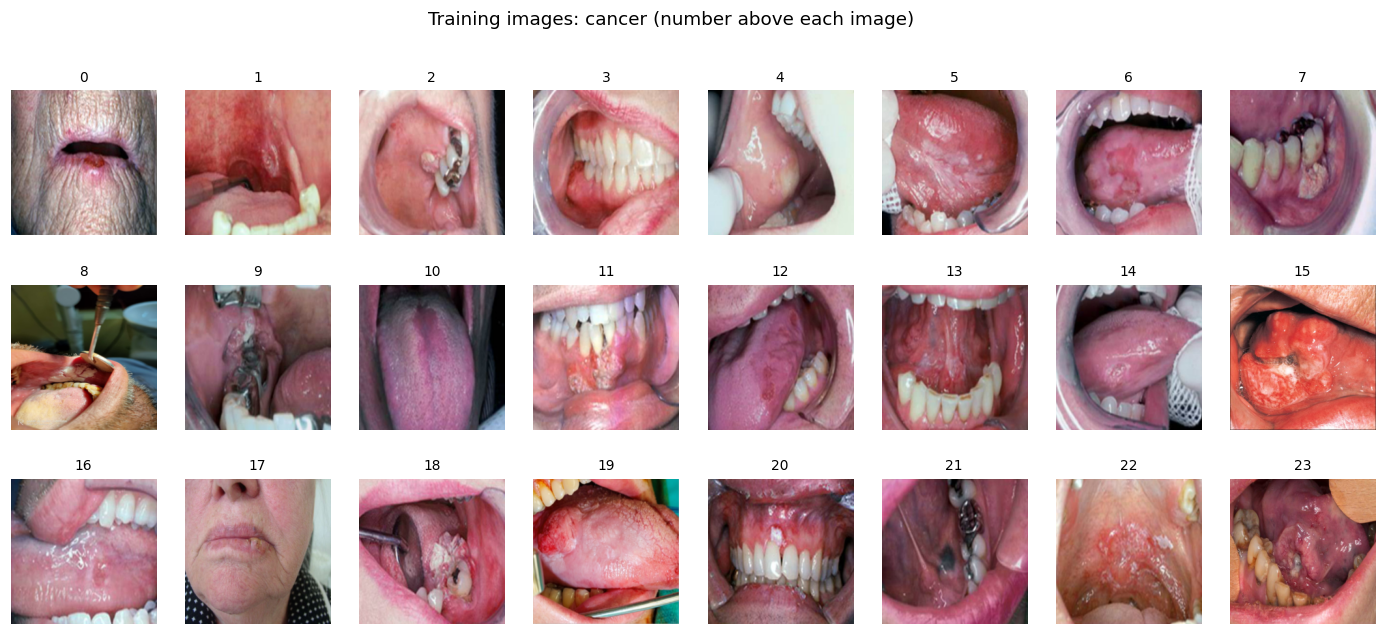

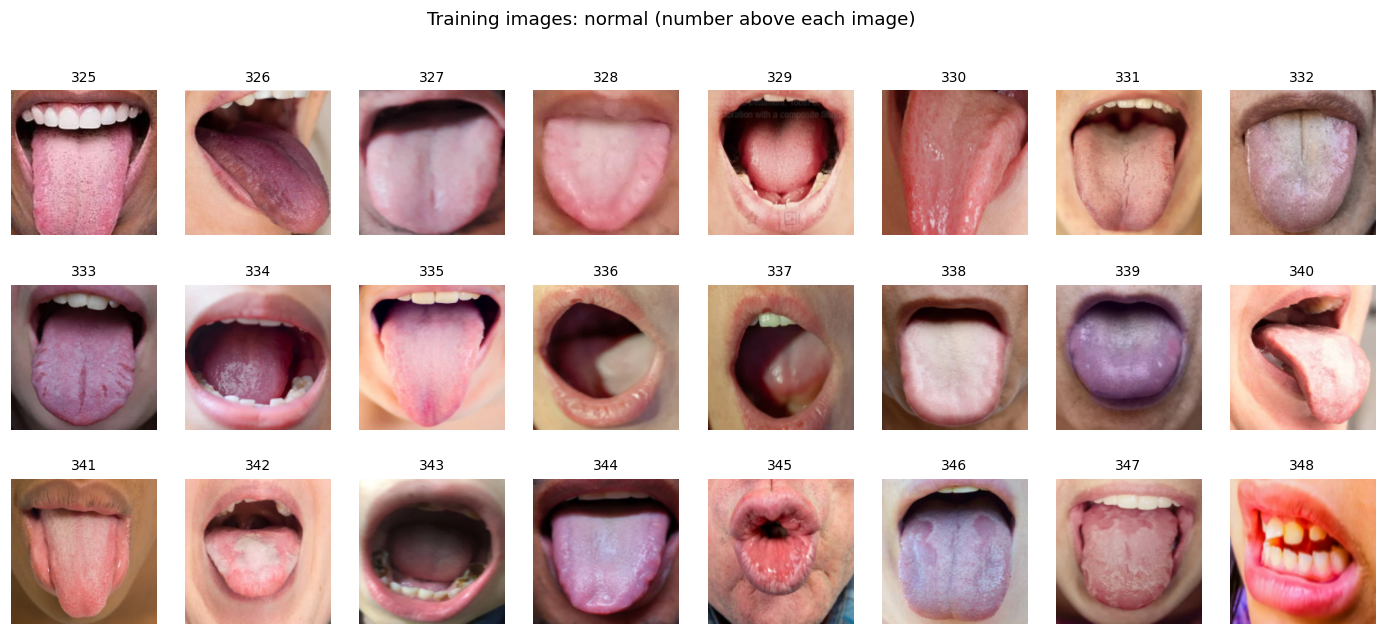

In [ ]:
# Part 1: show candidates with their numbers
import matplotlib.pyplot as plt
for cls, name in ((1, "cancer"), (0, "normal")):
    idx = np.where(DATA["train"]["y"] == cls)[0][:24]
    fig, axs = plt.subplots(3, 8, figsize=(16, 6.5))
    for a, i in zip(axs.ravel(), idx):
        a.imshow(DATA["train"]["X"][i]); a.set_title(str(i), fontsize=9); a.axis("off")
    fig.suptitle(f"Training images: {name} (number above each image)"); plt.show()

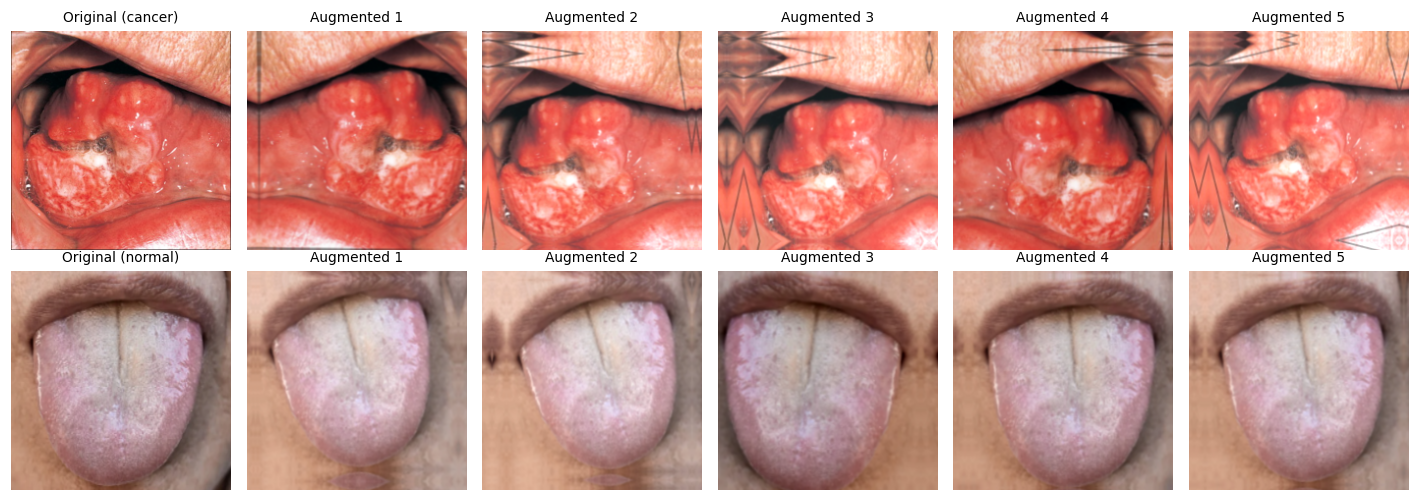

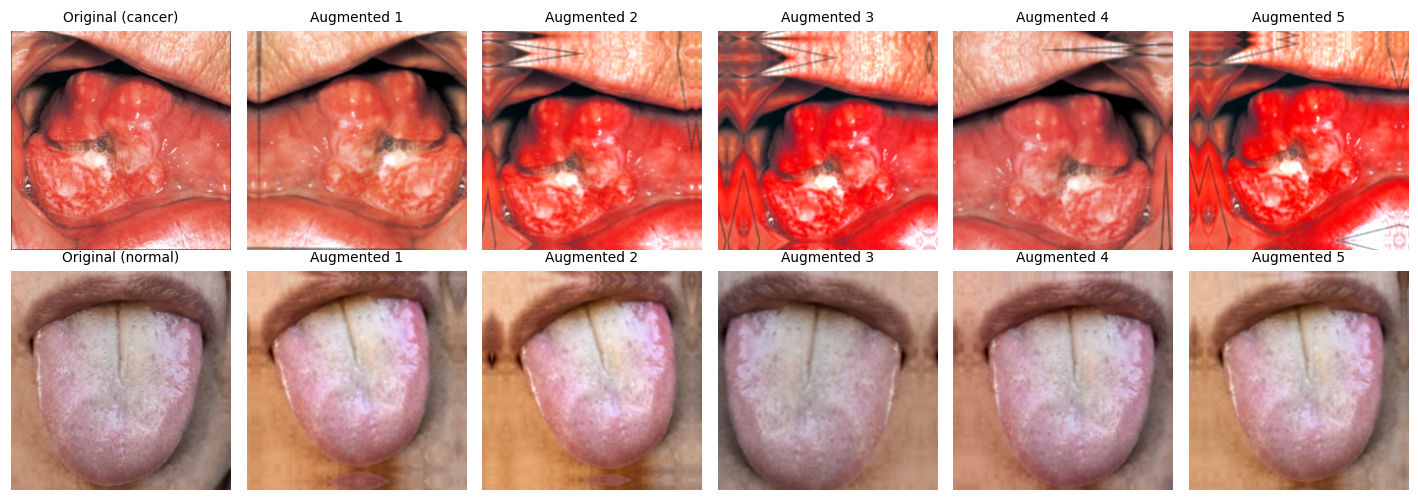

In [ ]:
# Part 2: indices of the example images shown in Figure S6
CANCER_IDX, NORMAL_IDX = 15, 332
from matplotlib.ticker import MaxNLocator
for kind in ("standard", "color"):
    aug = augmenter(123, kind)
    fig, axs = plt.subplots(2, 6, figsize=(13, 4.6))
    for r, (i, lab) in enumerate(((CANCER_IDX, "cancer"), (NORMAL_IDX, "normal"))):
        img = DATA["train"]["X"][i].astype("float32")
        axs[r, 0].imshow(img.astype("uint8")); axs[r, 0].set_title(f"Original ({lab})", fontsize=9)
        for c in range(1, 6):
            out = np.clip(np.asarray(aug(img[None], training=True))[0], 0, 255).astype("uint8")
            axs[r, c].imshow(out); axs[r, c].set_title(f"Augmented {c}", fontsize=9)
        for a in axs[r]: a.axis("off")
    fig.tight_layout()
    fig.savefig(FIGS / f"Figure_augmentation_examples_{kind}_v2.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIGS / f"Figure_augmentation_examples_{kind}_v2.pdf", bbox_inches="tight"); plt.show()

## Step 4 - Training worker (each small group of runs is trained in a fresh process, so Colab memory never fills up)

In [ ]:
%%writefile /content/r1_worker.py
import sys
sys.path.insert(0, "/content")
from r1_common import train_run
args = sys.argv[1:]
for i in range(0, len(args), 3):
    train_run(args[i], args[i + 1], int(args[i + 2]))

Overwriting /content/r1_worker.py


## Step 5 - Run all experiments (completed runs are skipped when the notebook is re-run)

In [ ]:
pending = [j for j in JOBS if not (RUNS / j[0] / f"{j[1]}_seed{j[2]}" / "done.json").exists()]
print(f"{len(JOBS) - len(pending)} runs already finished, {len(pending)} to go")
t_all, CHUNK = time.time(), 4
for k in range(0, len(pending), CHUNK):
    chunk = pending[k:k + CHUNK]
    args = [str(a) for job in chunk for a in job]
    print(f"--- runs {k + 1}-{k + len(chunk)} of {len(pending)} | {(time.time() - t_all) / 60:.0f} min elapsed")
    r = subprocess.run([sys.executable, "/content/r1_worker.py", *args], capture_output=True, text=True)
    print("\n".join(l for l in r.stdout.splitlines() if l.startswith(("[done]", "[skip]"))))
    if r.returncode != 0:
        print("ERROR in this group - last lines of the log:\n", "\n".join(r.stderr.splitlines()[-15:]))
        break
print(f"Finished in {(time.time() - t_all) / 3600:.2f} h")

32 runs already finished, 12 to go
--- runs 1-4 of 12 | 0 min elapsed
[done] baseline   VGG16          seed  3 | epochs 10+24 | 3.71 min
[done] baseline   VGG16          seed  4 | epochs 10+15 | 2.34 min
[done] baseline   MobileNetV2    seed  3 | epochs 10+14 | 1.35 min
[done] baseline   MobileNetV2    seed  4 | epochs 10+6 | 0.94 min
--- runs 5-8 of 12 | 9 min elapsed
[done] baseline   DenseNet121    seed  3 | epochs 10+13 | 3.5 min
[done] baseline   DenseNet121    seed  4 | epochs 10+19 | 3.5 min
[done] baseline   EfficientNetB0 seed  3 | epochs 9+18 | 2.19 min
[done] baseline   EfficientNetB0 seed  4 | epochs 10+15 | 1.95 min
--- runs 9-12 of 12 | 20 min elapsed
[done] baseline   Xception       seed  3 | epochs 10+12 | 3.18 min
[done] baseline   Xception       seed  4 | epochs 10+19 | 3.87 min
[done] baseline   InceptionV3    seed  3 | epochs 10+13 | 2.38 min
[done] baseline   InceptionV3    seed  4 | epochs 10+16 | 2.35 min
Finished in 0.53 h


In [ ]:
import glob
info = pd.DataFrame([json.load(open(p)) for p in glob.glob(str(RUNS / "*" / "*" / "done.json"))])
print(len(info), "finished runs\n")
print(info.groupby("experiment").agg(runs=("seed", "size"), seeds=("seed", lambda s: sorted(s)),
                                     avg_minutes=("minutes", "mean")).round(1))
missing = [f for f in glob.glob(str(RUNS / "*" / "*")) if not os.path.exists(os.path.join(f, "preds.csv"))]
print("\nRuns with missing predictions:", missing if missing else "none")

44 finished runs

            runs                                       seeds  avg_minutes
experiment                                                               
baseline      14  [3, 3, 3, 3, 3, 3, 3, 4, 4, 4, 4, 4, 4, 4]          2.6
color_aug      5                             [0, 1, 2, 3, 4]          2.3
frozen         5                             [0, 1, 2, 3, 4]          1.4
full_ft        5                             [0, 1, 2, 3, 4]          2.7
no_aug         5                             [0, 1, 2, 3, 4]          2.6
patience15     5                             [0, 1, 2, 3, 4]          4.5
scratch        5                             [0, 1, 2, 3, 4]          8.2

Runs with missing predictions: none


## Step 6 - Collect results
Seeds 0-2 of the paper's protocol are read from `results_v2` (not retrained). Their external predictions are computed once from the stored checkpoints and saved in `results_reviewer1`; `results_v2` is not modified.

In [ ]:
BASE_EXT = OUT / "baseline_v2_external"; BASE_EXT.mkdir(exist_ok=True)

def v2_external(name, seed):
    f = BASE_EXT / f"{name}_seed{seed}.csv"
    if not f.exists():
        model, _ = build_model(name, seed, weights=None)
        model.load_weights(RESULTS_V2 / "runs" / f"{name}_seed{seed}" / "best.weights.h5")
        pd.DataFrame({"split": "external", "file": DATA["external"]["df"].ext_path,
                      "patient_id": DATA["external"]["df"].patient_id, "y": DATA["external"]["y"],
                      "prob": predict(model, DATA["external"]["X"])}).to_csv(f, index=False)
        del model; keras.backend.clear_session()
    return pd.read_csv(f)

def get_run(exp, name, seed):
    # returns (preds, history) or None if the run does not exist yet
    if exp == "baseline" and seed <= 2:
        r = RESULTS_V2 / "runs" / f"{name}_seed{seed}"
        if not (r / "done.json").exists(): return None
        pr = pd.read_csv(r / "preds.csv")
        return pd.concat([pr, v2_external(name, seed)], ignore_index=True), pd.read_csv(r / "history.csv")
    r = RUNS / exp / f"{name}_seed{seed}"
    if not (r / "done.json").exists(): return None
    return pd.read_csv(r / "preds.csv"), pd.read_csv(r / "history.csv")

rows = []
for exp in EXPERIMENTS:
    for name in MODELS:
        for seed in ALL_SEEDS:
            run = get_run(exp, name, seed)
            if run is None: continue
            pr, hist = run
            row = dict(experiment=exp, model=name, seed=seed)
            for part, tag in (("val", "val"), ("test", "int"), ("external", "ext")):
                d = pr[pr.split == part]
                for k, v in metrics(d.y.values, d.prob.values).items():
                    row[f"{tag}_{k}"] = v
            s1, s2 = hist[hist.stage == 1], hist[hist.stage == 2]
            row.update(stage1_epochs=len(s1), stage2_epochs=len(s2),
                       stage1_best_epoch=int(s1.val_loss.values.argmin() + 1),
                       stage2_best_epoch=int(s2.val_loss.values.argmin() + 1) if len(s2) else np.nan)
            rows.append(row)
R = pd.DataFrame(rows)
R.to_csv(TABLES / "all_runs_metrics.csv", index=False)
print(len(R), "runs collected"); display(R.groupby(["experiment", "model"]).size().unstack(fill_value=0))

65 runs collected


model,DenseNet121,EfficientNetB0,InceptionV3,MobileNetV2,ResNet50,VGG16,Xception
experiment,,,,,,,
baseline,5,5,5,5,5,5,5
color_aug,0,0,0,0,5,0,0
frozen,0,0,0,0,5,0,0
full_ft,0,0,0,0,5,0,0
no_aug,0,0,0,0,5,0,0
patience15,0,0,0,0,5,0,0
scratch,0,0,0,0,5,0,0


## Step 7 - Tables for the revision

In [ ]:
def msd(x, d=3):
    x = pd.Series(x).dropna()
    return f"{x.mean():.{d}f} ± {x.std(ddof=1):.{d}f}" if len(x) > 1 else (f"{x.mean():.{d}f}" if len(x) else "")

COLS = [("int_auc", "Internal AUC"), ("int_balanced_accuracy", "Internal bal. acc."), ("int_sensitivity", "Internal sens."),
        ("int_specificity", "Internal spec."), ("ext_auc", "External AUC*"), ("ext_balanced_accuracy", "External bal. acc.*"),
        ("ext_specificity", "External spec.*")]

# ---- Table A: transfer-learning, patience and augmentation experiments (ResNet50, seeds 0-4) ----
abl = R[(R.model == PRIMARY_MODEL) & R.seed.isin(ABLATION_SEEDS)]
order = ["baseline", "scratch", "frozen", "full_ft", "patience15", "no_aug", "color_aug"]
tA = []
for exp in order:
    d = abl[abl.experiment == exp]
    if d.empty: continue
    tA.append({"Experiment": LABELS[exp], "Seeds": len(d),
               "Epochs (stage 1 + stage 2)": f"{d.stage1_epochs.mean():.1f} + {d.stage2_epochs.mean():.1f}",
               "Val. AUC": msd(d.val_auc), **{lab: msd(d[c]) for c, lab in COLS}})
tA = pd.DataFrame(tA); tA.to_csv(TABLES / "tableR1_ablation_resnet50.csv", index=False)
print("Table R1-A. ResNet50, mean ± SD over seeds 0-4 (* external = exploratory)"); display(tA)

# per-seed difference from the paper's protocol (same seed), with 95% CI over seeds
diff = []
base = abl[abl.experiment == "baseline"].set_index("seed")
for exp in order[1:]:
    d = abl[abl.experiment == exp].set_index("seed")
    common = d.index.intersection(base.index)
    for c, lab in (("int_auc", "Internal AUC"), ("ext_auc", "External AUC")):
        x = (d.loc[common, c] - base.loc[common, c]).values
        if len(x) > 1:
            ci = stats.t.interval(0.95, len(x) - 1, loc=x.mean(), scale=stats.sem(x))
            diff.append({"Experiment": LABELS[exp], "Metric": lab, "Mean difference vs paper": round(x.mean(), 3),
                         "95% CI": f"{ci[0]:.3f} to {ci[1]:.3f}", "Seeds": len(x)})
diff = pd.DataFrame(diff); diff.to_csv(TABLES / "tableR1_ablation_differences.csv", index=False)
print("Paired difference (experiment - paper protocol, same seed)"); display(diff)

# ---- Table B: why training stops early (paper protocol, ResNet50) ----
ep = R[(R.experiment == "baseline") & (R.model == PRIMARY_MODEL)].sort_values("seed")
ep = ep[["seed", "stage1_epochs", "stage1_best_epoch", "stage2_epochs", "stage2_best_epoch"]]
ep.to_csv(TABLES / "tableR1_epochs_resnet50.csv", index=False)
print(f"Table R1-B. ResNet50 epochs. Stage 1 reached its {HEAD_EPOCHS}-epoch limit in "
      f"{(ep.stage1_epochs == HEAD_EPOCHS).sum()} of {len(ep)} runs; "
      f"stage-2 best epoch median {ep.stage2_best_epoch.median():.0f} (range {ep.stage2_best_epoch.min():.0f}-{ep.stage2_best_epoch.max():.0f})")
display(ep)

# ---- Table C: seed variability, all models, paper protocol ----
bl = R[R.experiment == "baseline"]
lock = json.load(open(RESULTS_V2 / "lock.json"))["locked_seed"]
tC = []
for name in MODELS:
    d = bl[bl.model == name]
    if d.empty: continue
    row = {"Model": name, "Seeds": len(d)}
    for c, lab in (("int_auc", "Internal AUC"), ("int_balanced_accuracy", "Internal bal. acc."),
                   ("ext_auc", "External AUC*"), ("ext_specificity", "External spec.*")):
        row[lab + " mean ± SD"] = msd(d[c]); row[lab + " range"] = f"{d[c].min():.3f}-{d[c].max():.3f}"
    row["Internal AUC, seeds 0-2 only"] = msd(d[d.seed <= 2].int_auc)
    lk = d[d.seed == lock[name]]
    row["Locked seed internal AUC (percentile among seeds)"] = (
        f"{lk.int_auc.iloc[0]:.3f} ({stats.percentileofscore(d.int_auc, lk.int_auc.iloc[0]):.0f}%)" if len(lk) else "")
    tC.append(row)
tC = pd.DataFrame(tC); tC.to_csv(TABLES / "tableR1_seed_variability.csv", index=False)
print("Table R1-C. Variability over seeds, paper protocol (* external = exploratory)"); display(tC)

Table R1-A. ResNet50, mean ± SD over seeds 0-4 (* external = exploratory)


,Experiment,Seeds,Epochs (stage 1 + stage 2),Val. AUC,Internal AUC,Internal bal. acc.,Internal sens.,Internal spec.,External AUC*,External bal. acc.*,External spec.*
0,Top 30% fine-tuned (paper),5,8.6 + 10.6,0.978 ± 0.004,0.971 ± 0.002,0.906 ± 0.006,0.911 ± 0.013,0.901 ± 0.017,0.861 ± 0.009,0.688 ± 0.016,0.406 ± 0.049
1,From scratch (random weights),5,30.4 + 0.0,0.895 ± 0.029,0.866 ± 0.016,0.793 ± 0.016,0.812 ± 0.051,0.775 ± 0.075,0.580 ± 0.036,0.541 ± 0.019,0.233 ± 0.090
2,Frozen ImageNet backbone (head only),5,13.8 + 0.0,0.973 ± 0.006,0.966 ± 0.008,0.905 ± 0.010,0.908 ± 0.028,0.901 ± 0.028,0.819 ± 0.025,0.658 ± 0.034,0.358 ± 0.087
3,All layers fine-tuned,5,8.6 + 7.8,0.979 ± 0.004,0.970 ± 0.005,0.903 ± 0.007,0.894 ± 0.014,0.913 ± 0.027,0.864 ± 0.014,0.689 ± 0.032,0.406 ± 0.072
4,"Patience 15, stage 1 up to 30 epochs",5,26.6 + 20.0,0.981 ± 0.003,0.974 ± 0.002,0.908 ± 0.006,0.908 ± 0.005,0.907 ± 0.008,0.860 ± 0.008,0.692 ± 0.017,0.410 ± 0.042
5,No augmentation,5,10.0 + 6.0,0.981 ± 0.002,0.964 ± 0.003,0.903 ± 0.006,0.880 ± 0.013,0.927 ± 0.015,0.830 ± 0.009,0.665 ± 0.016,0.389 ± 0.034
6,Standard + colour augmentation,5,9.2 + 9.0,0.979 ± 0.003,0.973 ± 0.002,0.907 ± 0.010,0.904 ± 0.026,0.910 ± 0.016,0.865 ± 0.009,0.702 ± 0.024,0.439 ± 0.063


Paired difference (experiment - paper protocol, same seed)


,Experiment,Metric,Mean difference vs paper,95% CI,Seeds
0,From scratch (random weights),Internal AUC,-0.105,-0.127 to -0.084,5
1,From scratch (random weights),External AUC,-0.281,-0.321 to -0.241,5
2,Frozen ImageNet backbone (head only),Internal AUC,-0.006,-0.015 to 0.004,5
3,Frozen ImageNet backbone (head only),External AUC,-0.042,-0.082 to -0.002,5
4,All layers fine-tuned,Internal AUC,-0.002,-0.008 to 0.005,5
5,All layers fine-tuned,External AUC,0.003,-0.008 to 0.015,5
6,"Patience 15, stage 1 up to 30 epochs",Internal AUC,0.003,0.001 to 0.005,5
7,"Patience 15, stage 1 up to 30 epochs",External AUC,-0.001,-0.006 to 0.005,5
8,No augmentation,Internal AUC,-0.007,-0.013 to -0.002,5
9,No augmentation,External AUC,-0.031,-0.051 to -0.010,5


Table R1-B. ResNet50 epochs. Stage 1 reached its 10-epoch limit in 3 of 5 runs; stage-2 best epoch median 4 (range 3-11)


,seed,stage1_epochs,stage1_best_epoch,stage2_epochs,stage2_best_epoch
0,0,10,10,9,4.0
1,1,7,2,9,4.0
2,2,10,7,8,3.0
3,3,6,1,16,11.0
4,4,10,7,11,6.0


Table R1-C. Variability over seeds, paper protocol (* external = exploratory)


,Model,Seeds,Internal AUC mean ± SD,Internal AUC range,Internal bal. acc. mean ± SD,Internal bal. acc. range,External AUC* mean ± SD,External AUC* range,External spec.* mean ± SD,External spec.* range,"Internal AUC, seeds 0-2 only",Locked seed internal AUC (percentile among seeds)
0,ResNet50,5,0.971 ± 0.002,0.969-0.973,0.906 ± 0.006,0.897-0.912,0.861 ± 0.009,0.855-0.875,0.406 ± 0.049,0.320-0.440,0.972 ± 0.002,0.972 (80%)
1,VGG16,5,0.970 ± 0.006,0.964-0.977,0.904 ± 0.020,0.887-0.937,0.851 ± 0.008,0.839-0.859,0.503 ± 0.031,0.464-0.536,0.970 ± 0.005,0.975 (80%)
2,MobileNetV2,5,0.964 ± 0.003,0.960-0.967,0.887 ± 0.012,0.878-0.907,0.829 ± 0.006,0.820-0.835,0.409 ± 0.026,0.371-0.438,0.963 ± 0.004,0.967 (100%)
3,DenseNet121,5,0.967 ± 0.003,0.963-0.971,0.901 ± 0.009,0.888-0.912,0.834 ± 0.010,0.823-0.849,0.454 ± 0.041,0.403-0.495,0.967 ± 0.002,0.969 (80%)
4,EfficientNetB0,5,0.964 ± 0.002,0.961-0.967,0.906 ± 0.003,0.901-0.907,0.865 ± 0.007,0.858-0.874,0.591 ± 0.097,0.480-0.675,0.962 ± 0.001,0.961 (20%)
5,Xception,5,0.967 ± 0.003,0.964-0.973,0.905 ± 0.020,0.886-0.938,0.828 ± 0.007,0.821-0.837,0.414 ± 0.040,0.376-0.466,0.965 ± 0.001,0.966 (60%)
6,InceptionV3,5,0.957 ± 0.009,0.945-0.966,0.898 ± 0.008,0.888-0.910,0.789 ± 0.017,0.770-0.814,0.359 ± 0.060,0.274-0.428,0.951 ± 0.006,0.945 (20%)


## Step 8 - Figures for the revision

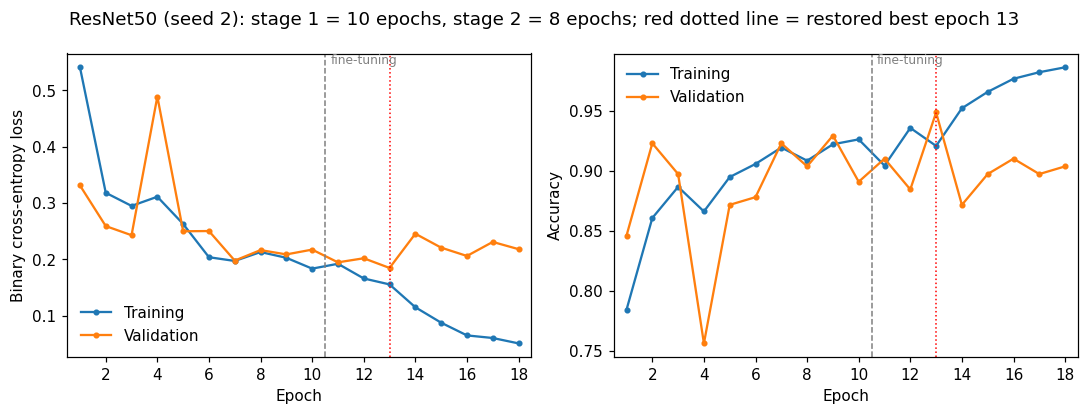

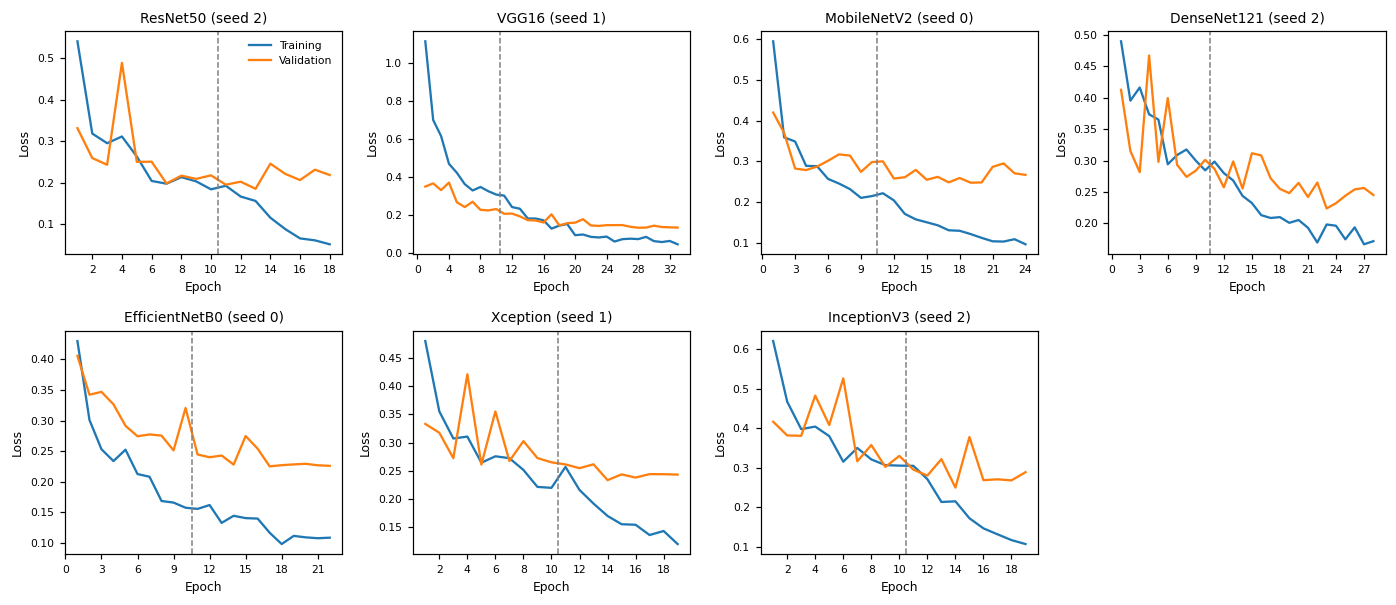

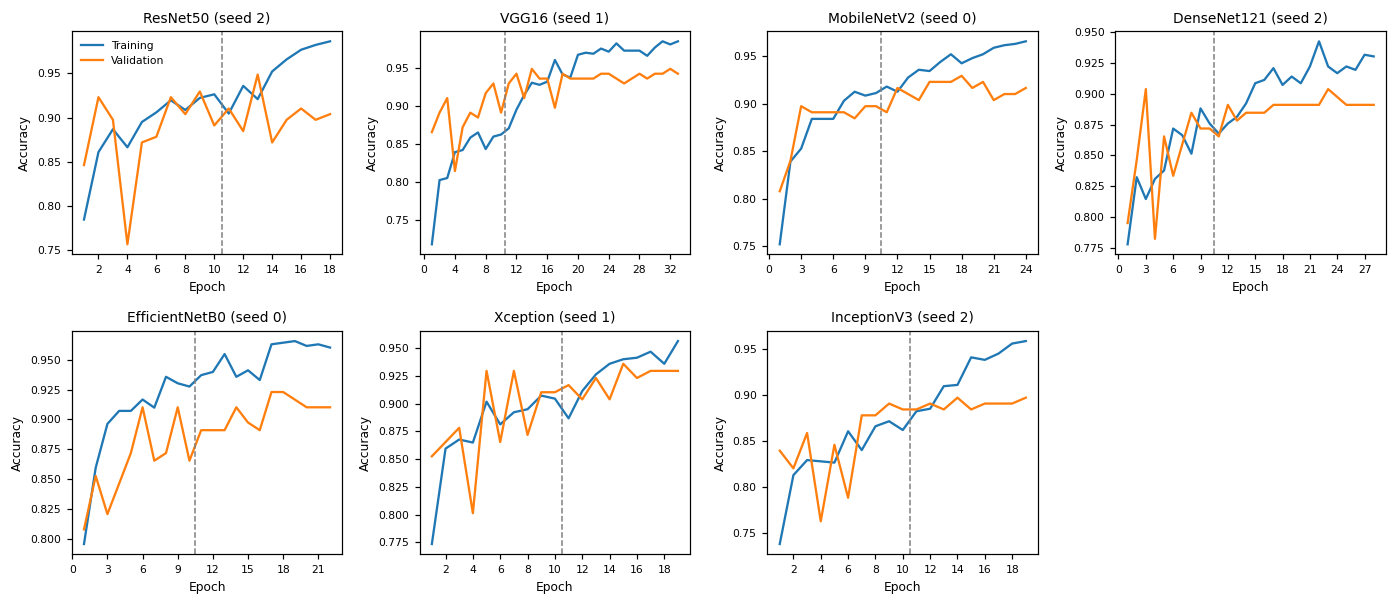

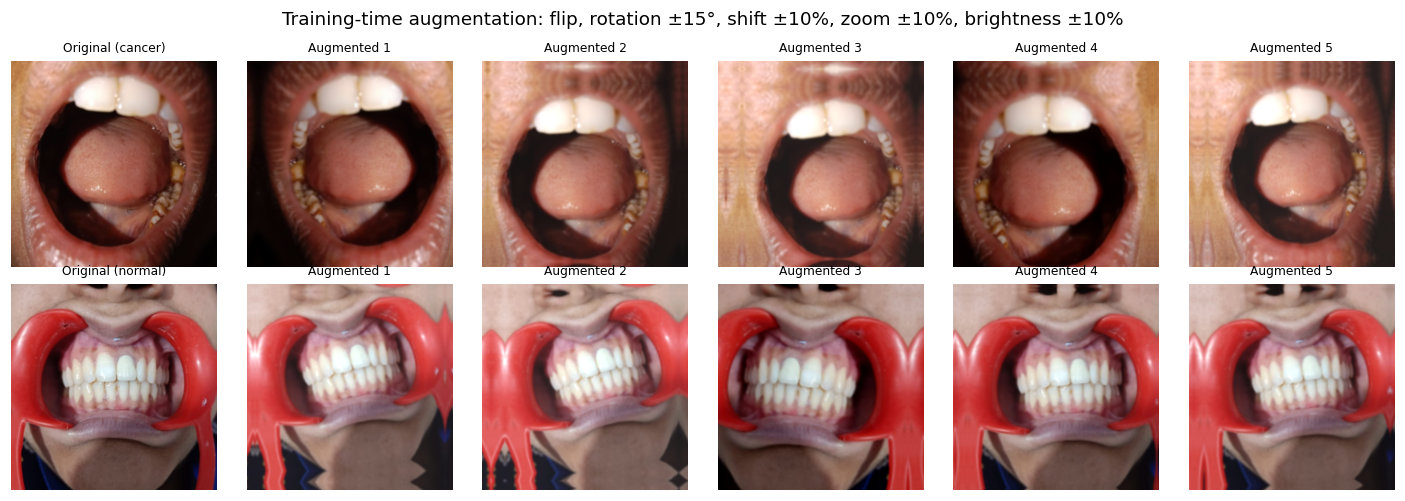

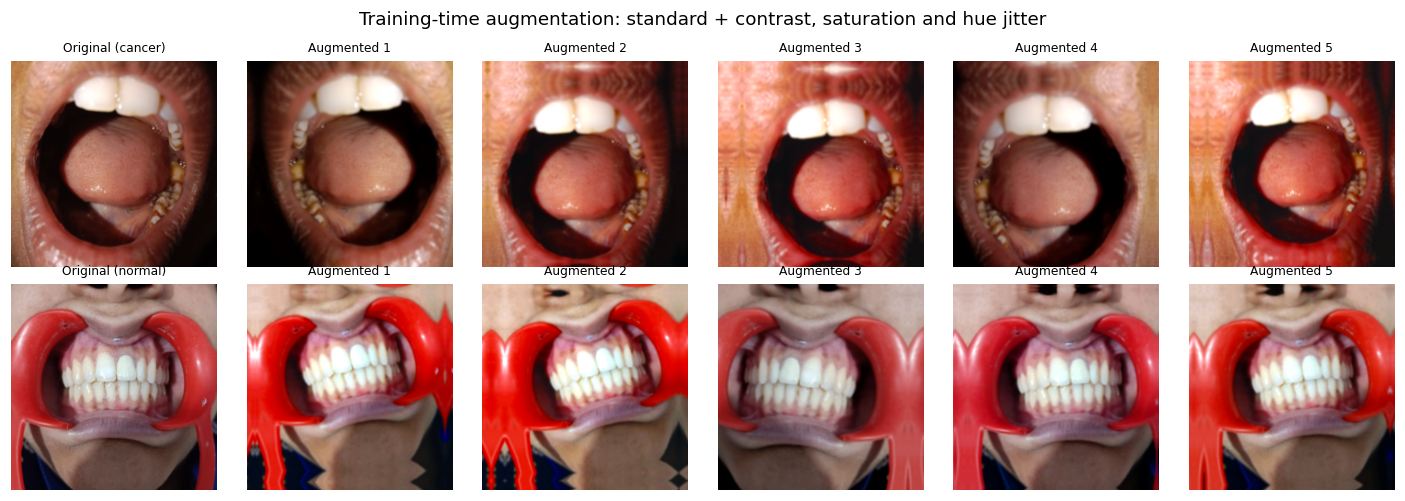

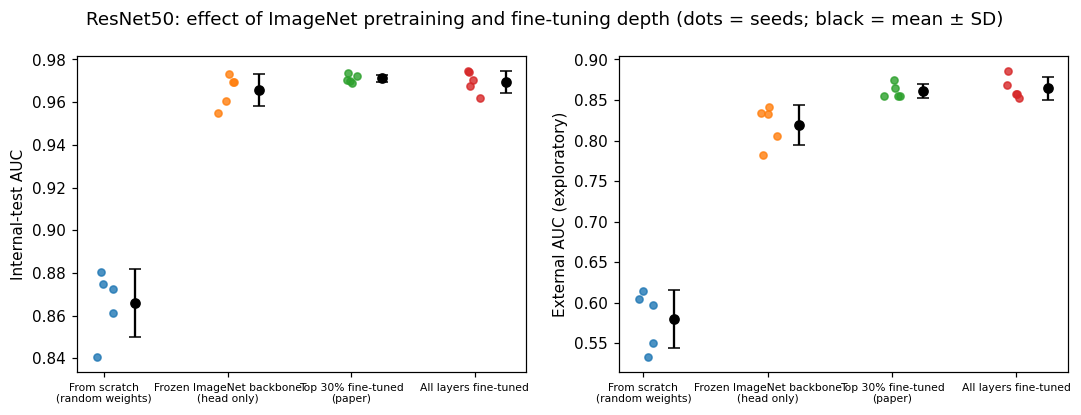

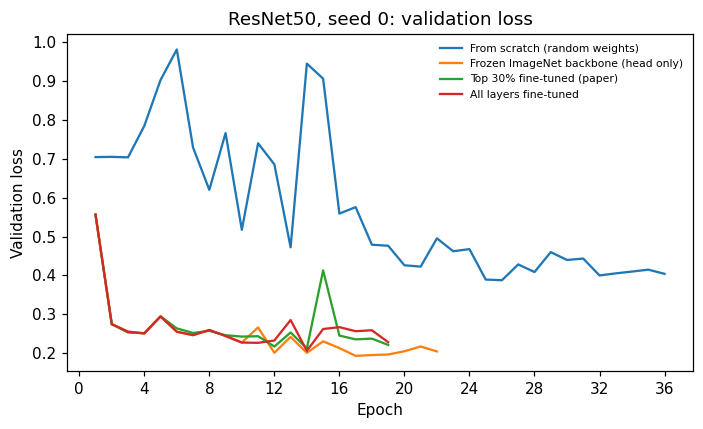

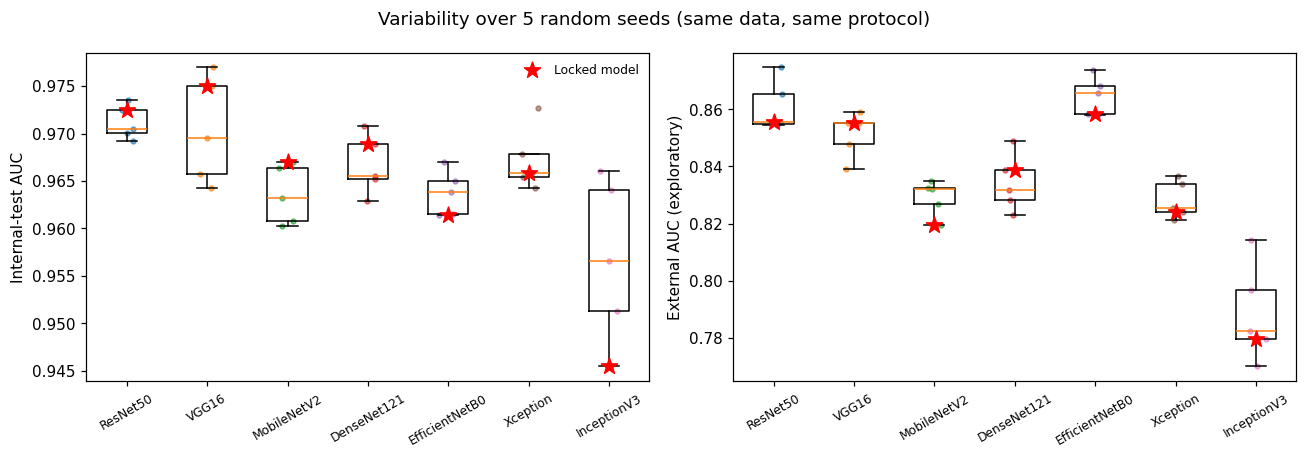

In [ ]:
def savefig(fig, name):
    fig.tight_layout(); fig.savefig(FIGS / f"{name}.png", bbox_inches="tight"); fig.savefig(FIGS / f"{name}.pdf", bbox_inches="tight")
    plt.show(); plt.close(fig)

# (1) Corrected Figure 3: whole-number epochs (locked ResNet50 run from results_v2)
s = lock[PRIMARY_MODEL]
h = pd.read_csv(RESULTS_V2 / "runs" / f"{PRIMARY_MODEL}_seed{s}" / "history.csv")
e1 = h[h.stage == 1].epoch.max()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a, key, lab in ((ax[0], "loss", "Binary cross-entropy loss"), (ax[1], "accuracy", "Accuracy")):
    a.plot(h.epoch, h[key], marker="o", ms=3, label="Training"); a.plot(h.epoch, h["val_" + key], marker="o", ms=3, label="Validation")
    a.axvline(e1 + 0.5, ls="--", c="grey", lw=1); a.text(e1 + 0.7, a.get_ylim()[1], "fine-tuning", va="top", fontsize=8, color="grey")
    best = h.loc[h.val_loss.idxmin(), "epoch"]; a.axvline(best, ls=":", c="red", lw=1)
    a.xaxis.set_major_locator(MaxNLocator(integer=True)); a.set_xlim(0.5, h.epoch.max() + 0.5)
    a.set_xlabel("Epoch"); a.set_ylabel(lab); a.legend(frameon=False)
fig.suptitle(f"{PRIMARY_MODEL} (seed {s}): stage 1 = {e1} epochs, stage 2 = {h.epoch.max() - e1} epochs; red dotted line = restored best epoch {best}")
savefig(fig, "Figure3_corrected_training_curves")

# (1b) Corrected Figures S1/S2: all models, whole-number epochs
for key, lab in (("loss", "Loss"), ("accuracy", "Accuracy")):
    fig, axs = plt.subplots(2, 4, figsize=(12.8, 5.6)); axs = axs.ravel(); axs[-1].axis("off")
    for a, name in zip(axs, MODELS):
        hh = pd.read_csv(RESULTS_V2 / "runs" / f"{name}_seed{lock[name]}" / "history.csv")
        a.plot(hh.epoch, hh[key], label="Training"); a.plot(hh.epoch, hh["val_" + key], label="Validation")
        a.axvline(hh[hh.stage == 1].epoch.max() + 0.5, ls="--", c="grey", lw=1)
        a.xaxis.set_major_locator(MaxNLocator(integer=True)); a.set_title(f"{name} (seed {lock[name]})", fontsize=9)
        a.set_xlabel("Epoch", fontsize=8); a.set_ylabel(lab, fontsize=8); a.tick_params(labelsize=7)
    axs[0].legend(fontsize=7, frameon=False)
    savefig(fig, f"FigureS_{key}_all_models_corrected")

# (2) Augmentation examples (training images only, as the network sees them during training)
rng = np.random.default_rng(1)
idx = [rng.choice(np.where(DATA["train"]["y"] == c)[0]) for c in (1, 0)]
for kind in ("standard", "color"):
    aug = augmenter(123, kind)
    fig, axs = plt.subplots(2, 6, figsize=(13, 4.6))
    for r, i in enumerate(idx):
        img = DATA["train"]["X"][i].astype("float32")
        axs[r, 0].imshow(img.astype("uint8")); axs[r, 0].set_title("Original" + (" (cancer)" if r == 0 else " (normal)"), fontsize=8)
        for c in range(1, 6):
            out = np.clip(np.asarray(aug(img[None], training=True))[0], 0, 255).astype("uint8")
            axs[r, c].imshow(out); axs[r, c].set_title(f"Augmented {c}", fontsize=8)
        for a in axs[r]: a.axis("off")
    fig.suptitle("Training-time augmentation: " + ("flip, rotation ±15°, shift ±10%, zoom ±10%, brightness ±10%" if kind == "standard"
                 else "standard + contrast, saturation and hue jitter"))
    savefig(fig, f"Figure_augmentation_examples_{kind}")

# (3) Transfer-learning comparison (ResNet50)
order_tl = [e for e in ["scratch", "frozen", "baseline", "full_ft"] if e in set(abl.experiment)]
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
for a, (c, lab) in zip(axs, (("int_auc", "Internal-test AUC"), ("ext_auc", "External AUC (exploratory)"))):
    for k, e in enumerate(order_tl):
        v = abl[abl.experiment == e][c]
        a.scatter(np.full(len(v), k) + rng.uniform(-0.08, 0.08, len(v)), v, s=22, alpha=0.8)
        a.errorbar(k + 0.25, v.mean(), yerr=v.std(ddof=1), fmt="o", c="black", capsize=4)
    a.set_xticks(range(len(order_tl)), [LABELS[e].replace(" (", "\n(") for e in order_tl], fontsize=7)
    a.set_ylabel(lab)
fig.suptitle("ResNet50: effect of ImageNet pretraining and fine-tuning depth (dots = seeds; black = mean ± SD)")
savefig(fig, "Figure_transfer_learning_comparison")

# validation-loss curves of the transfer-learning variants (seed 0)
fig, a = plt.subplots(figsize=(6.5, 4))
for e in order_tl:
    run = get_run(e, PRIMARY_MODEL, 0)
    if run: a.plot(run[1].epoch, run[1].val_loss, label=LABELS[e])
a.xaxis.set_major_locator(MaxNLocator(integer=True)); a.set_xlabel("Epoch"); a.set_ylabel("Validation loss")
a.set_title("ResNet50, seed 0: validation loss"); a.legend(fontsize=7, frameon=False)
savefig(fig, "Figure_transfer_learning_val_loss")

# (4) Seed variability, all models (paper protocol)
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
for a, (c, lab) in zip(axs, (("int_auc", "Internal-test AUC"), ("ext_auc", "External AUC (exploratory)"))):
    data = [bl[bl.model == m][c].values for m in MODELS]
    a.boxplot(data, widths=0.5, showfliers=False)
    for k, (m, v) in enumerate(zip(MODELS, data), 1):
        a.scatter(np.full(len(v), k) + rng.uniform(-0.12, 0.12, len(v)), v, s=10, alpha=0.6)
        lk = bl[(bl.model == m) & (bl.seed == lock[m])][c]
        if len(lk): a.scatter([k], lk, marker="*", s=120, c="red", zorder=5, label="Locked model" if k == 1 else None)
    a.set_xticks(range(1, len(MODELS) + 1), MODELS, rotation=30, fontsize=8); a.set_ylabel(lab)
axs[0].legend(frameon=False, fontsize=8)
fig.suptitle(f"Variability over {bl.groupby('model').size().max()} random seeds (same data, same protocol)")
savefig(fig, "Figure_seed_variability")

## Step 9 - Record and zip everything to download

In [ ]:
import shutil
env = dict(python=platform.python_version(), tensorflow=tf.__version__, keras=keras.__version__,
           gpu=os.popen("nvidia-smi --query-gpu=name --format=csv,noheader").read().strip() or "none",
           date=time.strftime("%Y-%m-%d %H:%M:%S"))
json.dump(dict(environment=env, experiments=EXPERIMENTS, scratch=dict(lr=SCRATCH_LR, epochs=SCRATCH_EPOCHS, patience=SCRATCH_PATIENCE),
               frozen_epochs=FROZEN_EPOCHS, color_aug=COLOR_AUG, ablation_seeds=ABLATION_SEEDS, all_seeds=ALL_SEEDS),
          open(OUT / "run_record.json", "w"), indent=2)
info = [json.load(open(p)) for p in RUNS.glob("*/*/done.json")]
pd.DataFrame(info).to_csv(TABLES / "training_runs_info.csv", index=False)
STAGE = OUT / "_download"                       # tables + figures only (model weights are too large to zip)
shutil.rmtree(STAGE, ignore_errors=True)
shutil.copytree(TABLES, STAGE / "tables"); shutil.copytree(FIGS, STAGE / "figures"); shutil.copy2(OUT / "run_record.json", STAGE)
zip_path = shutil.make_archive(str(PROJECT / "reviewer1_results_tables_figures"), "zip", STAGE)
shutil.rmtree(STAGE)
print("Download this file from Google Drive:", zip_path)

Download this file from Google Drive: /content/drive/MyDrive/oral project/reviewer1_results_tables_figures.zip
